<a href="https://colab.research.google.com/github/AnisaIntania/Natural-Language-Processing/blob/main/NLP_P5_02_NERTraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# install library
%pip install -q sklearn-crfsuite nltk scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 12.3 MB/s eta 0:00:00


In [3]:
#Make the necessary imports
from nltk.tag import pos_tag
from sklearn_crfsuite import CRF, metrics
from sklearn.metrics import make_scorer,confusion_matrix
from pprint import pprint
from sklearn.metrics import f1_score,classification_report
from sklearn.pipeline import Pipeline
import string
import warnings
warnings.filterwarnings('ignore')

In [4]:
def load__data_conll(file_path):
    myoutput,words,tags = [],[],[]
    fh = open(file_path)
    for line in fh:
        line = line.strip()
        if "\t" not in line:
            #Sentence ended.
            myoutput.append([words,tags])
            words,tags = [],[]
        else:
            word, tag = line.split("\t")
            words.append(word)
            tags.append(tag)
    fh.close()
    return myoutput

In [5]:
def sent2feats(sentence):
    feats = []
    sen_tags = pos_tag(sentence) #This format is specific to this POS tagger!
    for i in range(0,len(sentence)):
        word = sentence[i]
        wordfeats = {}
       #word features: word, prev 2 words, next 2 words in the sentence.
        wordfeats['word'] = word
        if i == 0:
            wordfeats["prevWord"] = wordfeats["prevSecondWord"] = "<S>"
        elif i==1:
            wordfeats["prevWord"] = sentence[0]
            wordfeats["prevSecondWord"] = "</S>"
        else:
            wordfeats["prevWord"] = sentence[i-1]
            wordfeats["prevSecondWord"] = sentence[i-2]
        #next two words as features
        if i == len(sentence)-2:
            wordfeats["nextWord"] = sentence[i+1]
            wordfeats["nextNextWord"] = "</S>"
        elif i==len(sentence)-1:
            wordfeats["nextWord"] = "</S>"
            wordfeats["nextNextWord"] = "</S>"
        else:
            wordfeats["nextWord"] = sentence[i+1]
            wordfeats["nextNextWord"] = sentence[i+2]

        #POS tag features: current tag, previous and next 2 tags.
        wordfeats['tag'] = sen_tags[i][1]
        if i == 0:
            wordfeats["prevTag"] = wordfeats["prevSecondTag"] = "<S>"
        elif i == 1:
            wordfeats["prevTag"] = sen_tags[0][1]
            wordfeats["prevSecondTag"] = "</S>"
        else:
            wordfeats["prevTag"] = sen_tags[i - 1][1]
            wordfeats["prevSecondTag"] = sen_tags[i - 2][1]
            # next two words as features
        if i == len(sentence) - 2:
            wordfeats["nextTag"] = sen_tags[i + 1][1]
            wordfeats["nextNextTag"] = "</S>"
        elif i == len(sentence) - 1:
            wordfeats["nextTag"] = "</S>"
            wordfeats["nextNextTag"] = "</S>"
        else:
            wordfeats["nextTag"] = sen_tags[i + 1][1]
            wordfeats["nextNextTag"] = sen_tags[i + 2][1]
        #That is it! You can add whatever you want!
        feats.append(wordfeats)
    return feats

In [6]:
#Extract features from the conll data, after loading it.
def get_feats_conll(conll_data):
    feats = []
    labels = []
    for sentence in conll_data:
        feats.append(sent2feats(sentence[0]))
        labels.append(sentence[1])
    return feats, labels

In [7]:
#Train a sequence model
def train_seq(X_train,Y_train,X_dev,Y_dev):
   # crf = CRF(algorithm='lbfgs', c1=0.1, c2=0.1, max_iterations=50, all_possible_states=True)
    crf = CRF(algorithm='lbfgs', c1=0.1, c2=10, max_iterations=50)#, all_possible_states=True)
    #Just to fit on training data
    crf.fit(X_train, Y_train)
    labels = list(crf.classes_)
    #testing:
    y_pred = crf.predict(X_dev)
    sorted_labels = sorted(labels, key=lambda name: (name[1:], name[0]))
    print(metrics.flat_f1_score(Y_dev, y_pred,average='weighted', labels=labels))
    print(metrics.flat_classification_report(Y_dev, y_pred, labels=sorted_labels, digits=3))
    #print(metrics.sequence_accuracy_score(Y_dev, y_pred))
    get_confusion_matrix(Y_dev, y_pred,labels=sorted_labels)

In [8]:
def print_cm(cm, labels):
    print("\n")
    """pretty print for confusion matrixes"""
    columnwidth = max([len(x) for x in labels] + [5])  # 5 is value length
    empty_cell = " " * columnwidth
    # Print header
    print("    " + empty_cell, end=" ")
    for label in labels:
        print("%{0}s".format(columnwidth) % label, end=" ")
    print()
    # Print rows
    for i, label1 in enumerate(labels):
        print("    %{0}s".format(columnwidth) % label1, end=" ")
        sum = 0
        for j in range(len(labels)):
            cell = "%{0}.0f".format(columnwidth) % cm[i, j]
            sum =  sum + int(cell)
            print(cell, end=" ")
        print(sum) #Prints the total number of instances per cat at the end.

In [9]:
#python-crfsuite does not have a confusion matrix function,
#so writing it using sklearn's confusion matrix and print_cm from github
def get_confusion_matrix(y_true,y_pred,labels):
    trues,preds = [], []
    for yseq_true, yseq_pred in zip(y_true, y_pred):
        trues.extend(yseq_true)
        preds.extend(yseq_pred)
    print_cm(confusion_matrix(trues,preds,labels),labels)

In [15]:
import nltk

nltk.download('averaged_perceptron_tagger_eng')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


True

In [18]:
# mengubah dataset menjadi dua kolom
def convert_conll(input_file, output_file):
    with open(input_file, "r", encoding="utf-8") as fin, \
         open(output_file, "w", encoding="utf-8") as fout:

        for line in fin:
            line = line.strip()

            if not line:
                fout.write("\n")
                continue

            parts = line.split()

            if len(parts) >= 4:
                fout.write(f"{parts[0]}\t{parts[-1]}\n")

convert_conll("train.txt", "train_fixed.txt")
convert_conll("test.txt", "test_fixed.txt")

print("Dataset berhasil diperbaiki!")

Dataset berhasil diperbaiki!


In [26]:
def train_seq(X_train, Y_train, X_test, Y_test):
    crf = CRF(
        algorithm="lbfgs",
        c1=0.1,
        c2=10,
        max_iterations=50,
        all_possible_transitions=True
    )

    crf.fit(X_train, Y_train)
    y_pred = crf.predict(X_test)

    labels = sorted(crf.classes_)

    print("\nWeighted F1-score:")
    print(metrics.flat_f1_score(
        Y_test, y_pred, average="weighted"
    ))

    print("\nClassification Report:")
    print(metrics.flat_classification_report(
        Y_test,
        y_pred,
        labels=labels,
        digits=3,
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt

    true_labels = [tag for sentence in Y_test for tag in sentence]
    pred_labels = [tag for sentence in y_pred for tag in sentence]

    cm = confusion_matrix(true_labels, pred_labels, labels=labels)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )
    disp.plot(xticks_rotation=45)
    plt.tight_layout()
    plt.show()

Memproses dataset...
Training a Sequence classification model with CRF

Weighted F1-score:
0.926185027829231

Classification Report:
              precision    recall  f1-score   support

       B-LOC      0.704     0.764     0.733      1668
      B-MISC      0.652     0.318     0.427       702
       B-ORG      0.674     0.562     0.613      1661
       B-PER      0.768     0.771     0.770      1617
       I-LOC      0.765     0.482     0.592       257
      I-MISC      0.625     0.509     0.561       216
       I-ORG      0.556     0.705     0.622       835
       I-PER      0.816     0.890     0.851      1156
           O      0.973     0.981     0.977     38323

    accuracy                          0.929     46435
   macro avg      0.726     0.665     0.683     46435
weighted avg      0.927     0.929     0.926     46435


Confusion Matrix:


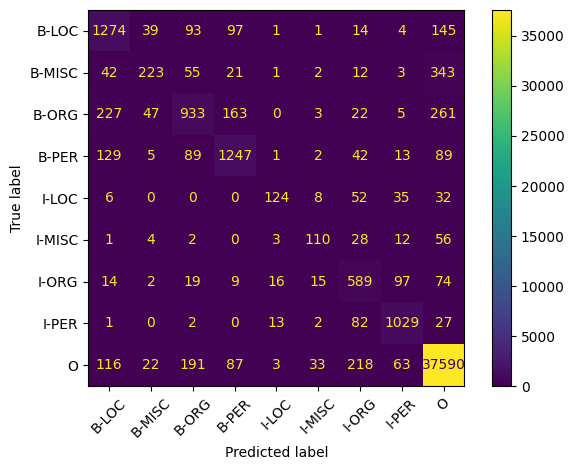

Done with sequence model


In [27]:
# training model
import os

def main():
    train_path = "train.txt"
    test_path = "test.txt"

    # cek file dataset
    if not os.path.exists(train_path):
        raise FileNotFoundError("File train.txt tidak ditemukan di Colab.")

    if not os.path.exists(test_path):
        raise FileNotFoundError("File test.txt tidak ditemukan di Colab.")

    print("Memproses dataset...")

    # konversi dataset menjadi format kata dan label NER
    def convert_conll(input_file, output_file):
        with open(input_file, "r", encoding="utf-8") as fin, \
             open(output_file, "w", encoding="utf-8") as fout:

            for line in fin:
                line = line.strip()

                if not line or line.startswith("-DOCSTART-"):
                    fout.write("\n")
                    continue

                parts = line.split()

                if len(parts) >= 4:
                    fout.write(f"{parts[0]}\t{parts[-1]}\n")

    convert_conll(train_path, "train_fixed.txt")
    convert_conll(test_path, "test_fixed.txt")

    conll_train = load__data_conll("train_fixed.txt")
    conll_dev = load__data_conll("test_fixed.txt")

    print("Training a Sequence classification model with CRF")

    feats, labels = get_feats_conll(conll_train)
    devfeats, devlabels = get_feats_conll(conll_dev)

    train_seq(feats, labels, devfeats, devlabels)

    print("Done with sequence model")

main()